# Indian Startup Success and Failure Analysis

## Dataset Understanding

This notebook is used to understand the basic structure and attributes of the Indian startup dataset before performing data cleaning and analysis.

In [1]:
import pandas as pd

## Loading the Dataset

The Indian startup dataset is loaded into a pandas DataFrame for analysis.

In [2]:
df = pd.read_excel("/content/indian_startup_success_failure_dataset.xlsx")

In [3]:
df.head()

,Name,Category_list,Funding_total_usd,Funding_rounds,State_code,Region,City,Founded_at,First_funding_at,Last_funding_at,Status,Outcome,Homepage_url,Permalink
0,1CLICK,Chat|Mobile,-,1,19.0,Bangalore,Bangalore,2012-11-01,2014-01-26,2014-01-26,acquired,Success,http://1click.io,/organization/1click
1,ABC Live,Advertising,25000,1,5.0,Chandigarh,Chandigarh,2007-12-05,2007-01-05,2007-01-05,closed,Failure,http://abclive.in,/organization/abc-live
2,Acision,Mobile,100000000,1,10.0,New Delhi,Gurgaon,1992-01-01,2010-10-05,2010-10-05,acquired,Success,http://www.acision.com,/organization/acision
3,Adhysteria,Classifieds|Curated Web|Video,10000,1,16.0,Mumbai,Mumbai,2007-09-01,2007-07-01,2007-07-01,closed,Failure,http://www.adhysteria.com,/organization/adhysteria
4,Alsbridge,BPO Services|Consulting|Outsourcing,-,1,10.0,New Delhi,Gurgaon,2003-01-01,2013-01-08,2013-01-08,closed,Failure,http://www.alsbridge.com,/organization/alsbridge


## Dataset Structure

The number of rows and columns is checked to understand the size of the dataset. The column names are also displayed to identify the attributes available for analysis.

In [4]:
df.shape

(129, 14)

In [5]:
df.columns

Index(['Name', 'Category_list', 'Funding_total_usd', 'Funding_rounds',
       'State_code', 'Region', 'City', 'Founded_at', 'First_funding_at',
       'Last_funding_at', 'Status', 'Outcome', 'Homepage_url', 'Permalink'],
      dtype='object')

## Data Types

The data types of the columns are checked to understand how each attribute is stored in the dataset.

In [6]:
df.dtypes

,0
Name,object
Category_list,object
Funding_total_usd,object
Funding_rounds,int64
State_code,float64
Region,object
City,object
Founded_at,object
First_funding_at,object
Last_funding_at,object


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               129 non-null    object 
 1   Category_list      123 non-null    object 
 2   Funding_total_usd  129 non-null    object 
 3   Funding_rounds     129 non-null    int64  
 4   State_code         126 non-null    float64
 5   Region             125 non-null    object 
 6   City               125 non-null    object 
 7   Founded_at         105 non-null    object 
 8   First_funding_at   129 non-null    object 
 9   Last_funding_at    129 non-null    object 
 10  Status             129 non-null    object 
 11  Outcome            129 non-null    object 
 12  Homepage_url       126 non-null    object 
 13  Permalink          129 non-null    object 
dtypes: float64(1), int64(1), object(12)
memory usage: 14.2+ KB


## Initial Statistical Summary

Basic descriptive statistics are displayed to get an initial understanding of the numerical attributes.

In [8]:
df.describe()

,Funding_rounds,State_code
count,129.000000,126.000000
mean,1.356589,15.873016
std,0.908282,7.085742
min,1.000000,2.000000
25%,1.000000,10.000000
50%,1.000000,16.000000
75%,1.000000,19.000000
max,9.000000,36.000000


In [9]:
df.describe(include='object')

,Name,Category_list,Funding_total_usd,Region,City,Founded_at,First_funding_at,Last_funding_at,Status,Outcome,Homepage_url,Permalink
count,129,123,129,125,125,105,129,129,129,129,126,129
unique,129,91,74,18,23,72,120,122,3,2,126,129
top,1CLICK,Software,-,Bangalore,Bangalore,2012-01-01,2007-01-01,2007-01-01,closed,Failure,http://1click.io,/organization/1click
freq,1,11,33,39,36,7,3,3,69,69,1,1


## Data Quality Assessment

Before cleaning the dataset, I checked it for missing values, duplicate records, inconsistent values and other possible data quality issues.

In [10]:
df.isnull().sum()

,0
Name,0
Category_list,6
Funding_total_usd,0
Funding_rounds,0
State_code,3
Region,4
City,4
Founded_at,24
First_funding_at,0
Last_funding_at,0


In [11]:
(df.isnull().sum()/len(df))*100

,0
Name,0.000000
Category_list,4.651163
Funding_total_usd,0.000000
Funding_rounds,0.000000
State_code,2.325581
Region,3.100775
City,3.100775
Founded_at,18.604651
First_funding_at,0.000000
Last_funding_at,0.000000


In [12]:
missing_data=pd.DataFrame({
    'missing count' : df.isnull().sum(),
    'missing percentage' : (df.isnull().sum()/len(df))*100
})

print(missing_data)

                   missing count  missing percentage
Name                           0            0.000000
Category_list                  6            4.651163
Funding_total_usd              0            0.000000
Funding_rounds                 0            0.000000
State_code                     3            2.325581
Region                         4            3.100775
City                           4            3.100775
Founded_at                    24           18.604651
First_funding_at               0            0.000000
Last_funding_at                0            0.000000
Status                         0            0.000000
Outcome                        0            0.000000
Homepage_url                   3            2.325581
Permalink                      0            0.000000


### Duplicate Records

Duplicate records are checked to ensure that the same observation is not counted more than once in the analysis.

In [13]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
124,False
125,False
126,False
127,False


In [14]:
df.duplicated(keep=False).sum()

np.int64(0)

no duplicates found

In [15]:
df['Name'].duplicated(keep=False).sum()

np.int64(0)

No duplicates found

#categorical columns

In [16]:
cat_col = df.select_dtypes(include='object').columns
cat_col

Index(['Name', 'Category_list', 'Funding_total_usd', 'Region', 'City',
       'Founded_at', 'First_funding_at', 'Last_funding_at', 'Status',
       'Outcome', 'Homepage_url', 'Permalink'],
      dtype='object')

In [17]:
for col in cat_col:
  print("\n",col)
  print(df[col].unique())


 Name
['1CLICK' 'ABC Live' 'Acision' 'Adhysteria' 'Alsbridge' 'AppLabs'
 'atOnePlace.com' 'Autoportal.com' 'Babyoye' 'beStylish.com' 'BigZop'
 'Black is Pink' 'Buyt.In' 'CarWale' 'Comat Technologies'
 'Cooptions Technologies' 'Crude Area'
 'Cultivate IT Solutions & Management Pvt. Ltd.' 'Daksh Infosoft'
 'DAS GROUP OF SOLUTIONS' 'Diditz' 'Diskover' 'EasyLink' 'eatshoplove'
 'Edserv Softsystems' 'Elitecore Technologies' 'Equitas Holdings'
 'Eventifier' 'Eventus Software Pvt' 'ExamHack Inc.' 'EximSoft-Trianz'
 'FAB BAG' 'Financial Information Network & Operations Pvt'
 'Fracktal works' 'FreeCharge' 'Frilp' 'Genii Technologies' 'GetVu'
 'Giftology' 'GigsJam' 'Gingersoft Media' 'Greenko Group' 'Guruji'
 'HealthcareMagic' 'HomeShop18' 'hoopos.com' 'HungryBuddies.com'
 'Hunner Retail India Private Limited' 'iBloom Technologies'
 'IBS Software Services (P)' 'igadget.asia' 'iGATE/Patni Computers'
 'IMImobile' "i'mma"
 'Immigration Overseas Reviews cherishes of No Complaints' 'IndiaEver.com'
 

In [18]:
for col in cat_col:
  print("\nColumn:",col)
  print(df[col].value_counts(dropna=False))


Column: Name
Name
1CLICK               1
ABC Live             1
Acision              1
Adhysteria           1
Alsbridge            1
                    ..
Worldzen Holdings    1
YourDOST             1
Zipdial              1
Ziva Software        1
Zuvvu                1
Name: count, Length: 129, dtype: int64

Column: Category_list
Category_list
Software                                                                                                       11
E-Commerce                                                                                                      9
NaN                                                                                                             6
Mobile                                                                                                          5
Finance                                                                                                         5
                                                                                  

### Numerical Value Check

Numerical columns are checked for invalid or suspicious values such as negative values, zero values, and unusually large values.

In [19]:
num_col = df.select_dtypes(include='number').columns
num_col

Index(['Funding_rounds', 'State_code'], dtype='object')

In [20]:
for col in num_col:
  print("\nColumn:", col)
  print("max:", df[col].max())
  print("min:", df[col].min())


Column: Funding_rounds
max: 9
min: 1

Column: State_code
max: 36.0
min: 2.0


In [21]:
for col in num_col:
    print("\nCOLUMN:", col)
    print("Zero values:", (df[col] == 0).sum())
    print("Negative values:", (df[col] < 0).sum())


COLUMN: Funding_rounds
Zero values: 0
Negative values: 0

COLUMN: State_code
Zero values: 0
Negative values: 0


### Outlier Analysis

Potential outliers in numerical variables are checked using the Interquartile Range (IQR) method. State code is not included because it represents categories rather than a numerical measurement.

Funding_total_usd — continuous numerical                        
Funding_rounds — discrete numerical

#Funding_total_usd

##

In [22]:
funding_numeric = pd.to_numeric(df['Funding_total_usd'], errors='coerce')
funding_numeric

,Funding_total_usd
0,NaN
1,25000.0
2,100000000.0
3,10000.0
4,NaN
...,...
124,4000000.0
125,400000.0
126,NaN
127,1700000.0


In [23]:
funding_numeric.describe()

,Funding_total_usd
count,9.600000e+01
mean,1.735986e+07
std,3.704689e+07
min,8.000000e+03
25%,2.875000e+05
50%,2.990000e+06
75%,1.425000e+07
max,2.419833e+08


In [24]:
q1_funding = funding_numeric.quantile(0.25)
q3_funding = funding_numeric.quantile(0.75)
iqr_funding = q3_funding - q1_funding

print("Q1:",q1_funding)
print("Q3:",q3_funding)
print("IQR:",iqr_funding)

Q1: 287500.0
Q3: 14250000.0
IQR: 13962500.0


In [25]:
lower_funding = q1_funding - 1.5*iqr_funding
upper_funding = q3_funding + 1.5*iqr_funding

print("Lower Bound:",lower_funding)
print("Upper Bound:",upper_funding)

Lower Bound: -20656250.0
Upper Bound: 35193750.0


In [26]:
funding_outliers = funding_numeric[
    (funding_numeric < lower_funding) | (funding_numeric > upper_funding)
]

funding_outliers


,Funding_total_usd
2,100000000.0
34,113000000.0
41,241983286.0
44,65000000.0
49,60000000.0
51,100000000.0
62,67000000.0
75,158750000.0
78,36000000.0
81,125000000.0


In [27]:
print("number of funding outliers:",len(funding_outliers))

number of funding outliers: 12


#funding_rounds

In [28]:
Q1_rounds = df['Funding_rounds'].quantile(0.25)
Q3_rounds = df['Funding_rounds'].quantile(0.75)

IQR_rounds = Q3_rounds - Q1_rounds

In [29]:
lower_rounds = Q1_rounds - 1.5 * IQR_rounds
upper_rounds = Q3_rounds + 1.5 * IQR_rounds

In [30]:
print("Q1:", Q1_rounds)
print("Q3:", Q3_rounds)
print("IQR:", IQR_rounds)
print("Lower Bound:", lower_rounds)
print("Upper Bound:", upper_rounds)

Q1: 1.0
Q3: 1.0
IQR: 0.0
Lower Bound: 1.0
Upper Bound: 1.0


In [31]:
round_outliers = df[
    (df['Funding_rounds'] < lower_rounds) |
    (df['Funding_rounds'] > upper_rounds)
]

round_outliers[['Name', 'Funding_rounds']]

,Name,Funding_rounds
8,Babyoye,2
13,CarWale,2
14,Comat Technologies,3
16,Crude Area,2
27,Eventifier,2
32,Financial Information Network & Operations Pvt,2
34,FreeCharge,2
35,Frilp,2
36,Genii Technologies,2
41,Greenko Group,2


### Investigating Funding Round Outliers

30 potential outliers were detected using the IQR method. These values are inspected before deciding whether they should be treated or retained.

In [32]:
round_outliers[['Name','Funding_rounds']].sort_values(
    by='Funding_rounds',
    ascending=False)

,Name,Funding_rounds
75,Myntra,9
112,TaxiForSure.com,4
44,HomeShop18,3
84,OneAssist,3
14,Comat Technologies,3
52,IMImobile,3
98,redBus.in,3
87,Parallocity,3
126,Zipdial,3
27,Eventifier,2


### Outlier Decision

The detected values appear to be valid funding activity rather than data errors. Therefore, these outliers will be retained for further analysis.

In [33]:
import matplotlib.pyplot as plt


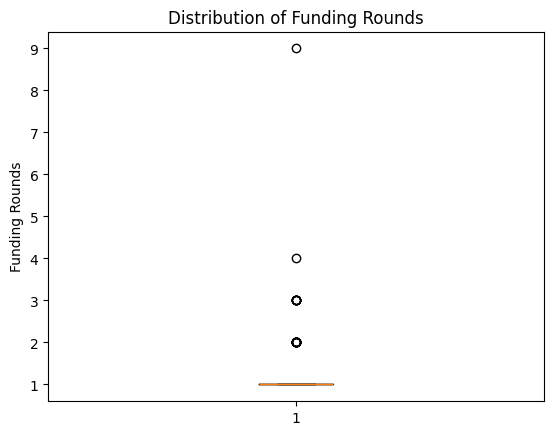

In [34]:
plt.boxplot(df['Funding_rounds'].dropna())
plt.ylabel('Funding Rounds')
plt.title('Distribution of Funding Rounds')
plt.show()

**Observation:** Most startups have one funding round. Higher values are statistical outliers but represent valid funding activity, so they are retained.

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               129 non-null    object 
 1   Category_list      123 non-null    object 
 2   Funding_total_usd  129 non-null    object 
 3   Funding_rounds     129 non-null    int64  
 4   State_code         126 non-null    float64
 5   Region             125 non-null    object 
 6   City               125 non-null    object 
 7   Founded_at         105 non-null    object 
 8   First_funding_at   129 non-null    object 
 9   Last_funding_at    129 non-null    object 
 10  Status             129 non-null    object 
 11  Outcome            129 non-null    object 
 12  Homepage_url       126 non-null    object 
 13  Permalink          129 non-null    object 
dtypes: float64(1), int64(1), object(12)
memory usage: 14.2+ KB


### Cleaning Funding Amount

`Funding_total_usd` is stored as text. It will be converted to numeric format so it can be analyzed correctly.

In [36]:
df['Funding_total_usd'].head(5)

,Funding_total_usd
0,-
1,25000
2,100000000
3,10000
4,-


In [37]:
df['Funding_total_usd'] = pd.to_numeric(
    df['Funding_total_usd'].replace('-', pd.NA),
    errors='coerce'
)

In [38]:
df['Funding_total_usd'].head(5)

,Funding_total_usd
0,NaN
1,25000.0
2,100000000.0
3,10000.0
4,NaN


In [39]:
df['Funding_total_usd'].dtype

dtype('float64')

### Missing Value Analysis

Missing values are evaluated before deciding whether to fill, retain, or remove them.

In [40]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})
missing[missing['Missing_Count']>0]

,Missing_Count,Missing_Percentage
Category_list,6,4.65
Funding_total_usd,33,25.58
State_code,3,2.33
Region,4,3.10
City,4,3.10
Founded_at,24,18.60
Homepage_url,3,2.33


In [41]:
df['Funding_total_usd'].describe()

,Funding_total_usd
count,9.600000e+01
mean,1.735986e+07
std,3.704689e+07
min,8.000000e+03
25%,2.875000e+05
50%,2.990000e+06
75%,1.425000e+07
max,2.419833e+08


### Handling Missing Values

Missing categorical information is labeled as `Unknown`, while missing funding and founding-date values are retained to avoid introducing artificial data.

In [42]:
columns_to_fill = ['Category_list', 'Region', 'City']

df[columns_to_fill] = df[columns_to_fill].fillna('Unknown')

In [43]:
df.isnull().sum()

,0
Name,0
Category_list,0
Funding_total_usd,33
Funding_rounds,0
State_code,3
Region,0
City,0
Founded_at,24
First_funding_at,0
Last_funding_at,0


### Final Data Quality Check

The cleaned dataset is reviewed for data types, missing values, and duplicate records before analysis.

In [44]:
df.duplicated().sum()

np.int64(0)

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               129 non-null    object 
 1   Category_list      129 non-null    object 
 2   Funding_total_usd  96 non-null     float64
 3   Funding_rounds     129 non-null    int64  
 4   State_code         126 non-null    float64
 5   Region             129 non-null    object 
 6   City               129 non-null    object 
 7   Founded_at         105 non-null    object 
 8   First_funding_at   129 non-null    object 
 9   Last_funding_at    129 non-null    object 
 10  Status             129 non-null    object 
 11  Outcome            129 non-null    object 
 12  Homepage_url       126 non-null    object 
 13  Permalink          129 non-null    object 
dtypes: float64(2), int64(1), object(11)
memory usage: 14.2+ KB


In [46]:
df.to_excel('startup_funding_cleaned.xlsx', index=False)